# 02 — What do supervised components emphasize?

**Question.** Interpret feature families, profile/departure variation and the prior shoulder PCA pattern.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'config/injury_supervised_reduction.yaml').exists())
if str(ROOT) not in sys.path:sys.path.insert(0,str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
from src.injury_analysis.supervised_reduction import inputs,read_table,OUT
from src.injury_analysis.supervised_workflow import ensure_stage
from src.injury_analysis import supervised_plots as plots
FORCE_RECOMPUTE=False
a,events,spec,matches=inputs()
pd.set_option('display.max_columns',18)


## Leading directions and interpretation
Fit axes on category-specific training risk sets only. The weights describe standardized source coordinates of the actual orthonormalized projection. Signs for plots are oriented toward higher training injury outcome; native weights remain available. Family sums of squared axis weights are geometric summaries, not explained injury risk or causal importance.

For profile/departure comparison, distinguish prior means from current relative deviations. Profile means use up to 20 prior outings, not a fixed lifetime trait. PLS is linear: mixing the two blocks does not test nonlinear interactions.

Using verified prediction artifacts.


Using verified interpretation artifacts.


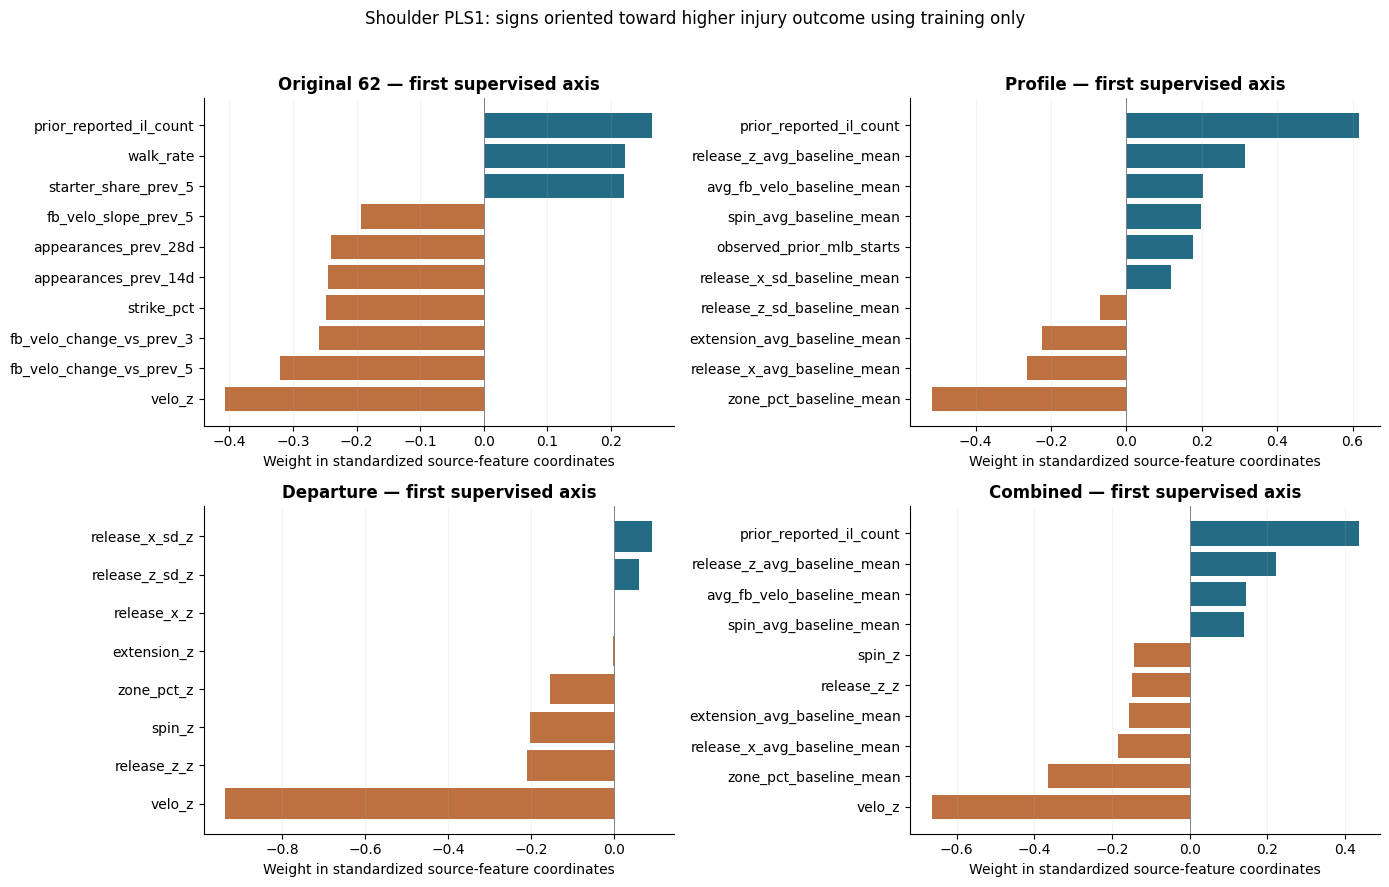

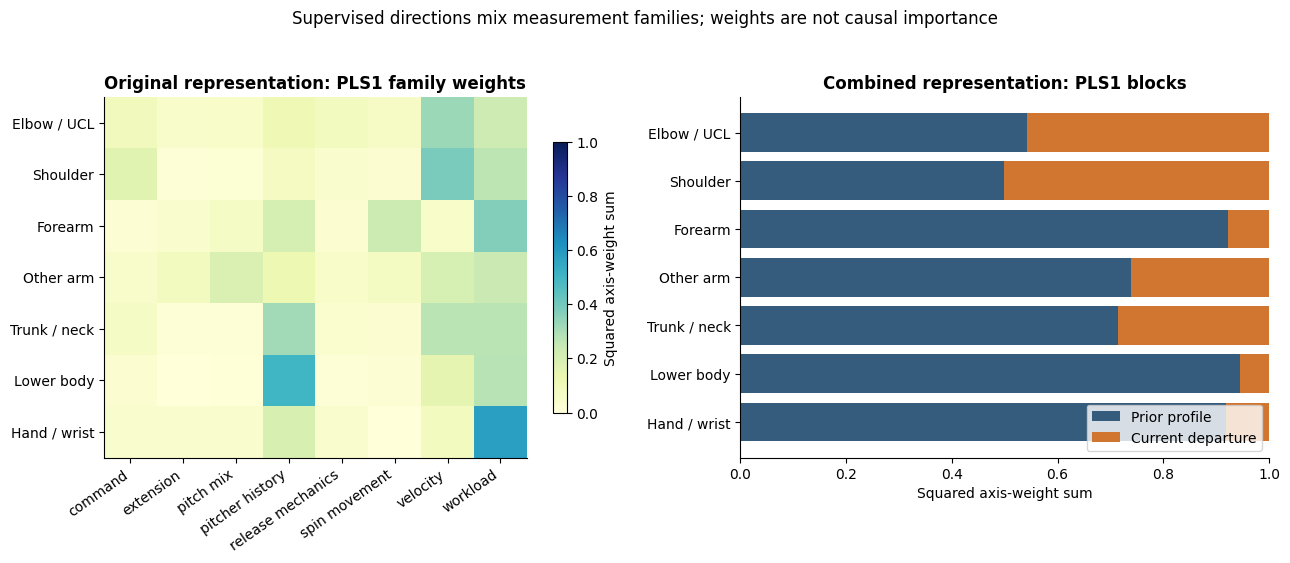

,category,block,method,component,family,squared_axis_weight
6,Elbow / UCL,Combined,PLS,1,Current departure,0.457843
7,Elbow / UCL,Combined,PLS,1,Prior profile,0.542157
27,Elbow / UCL,Departure,PLS,1,command,0.013356
28,Elbow / UCL,Departure,PLS,1,extension,0.066558
29,Elbow / UCL,Departure,PLS,1,release_mechanics,0.062089
...,...,...,...,...,...,...
683,Trunk / neck,Original 62,PLS,1,spin_movement,0.025057
684,Trunk / neck,Original 62,PLS,1,velocity,0.272643
685,Trunk / neck,Original 62,PLS,1,workload,0.270188
708,Trunk / neck,Profile,PLS,1,History/context,0.863780


,category,block,method,component,partition,between_pitcher_fraction,training_orientation,training_score_sd,rows
11,Elbow / UCL,Original 62,PLS,1,test,0.323059,-1.0,1.565551,27665
29,Elbow / UCL,Profile,PLS,1,test,0.949386,-1.0,1.341497,27665
47,Elbow / UCL,Departure,PLS,1,test,0.091048,-1.0,1.041910,27665
65,Elbow / UCL,Combined,PLS,1,test,0.569618,-1.0,1.210590,27665
83,Shoulder,Original 62,PLS,1,test,0.467735,-1.0,1.752864,27806
101,Shoulder,Profile,PLS,1,test,0.953022,1.0,1.083073,27806
119,Shoulder,Departure,PLS,1,test,0.096458,-1.0,1.031483,27806
137,Shoulder,Combined,PLS,1,test,0.704017,-1.0,1.069654,27806
155,Forearm,Original 62,PLS,1,test,0.829679,1.0,1.692905,27236
173,Forearm,Profile,PLS,1,test,0.975813,1.0,1.104661,27236


In [2]:
ensure_stage('prediction',a,events,spec,matches,force=False)
ensure_stage('interpretation',a,events,spec,matches,force=FORCE_RECOMPUTE)
plots.loadings_figure();plt.show()
plots.family_figure();plt.show()
display(read_table('component_family_weights').query("method=='PLS' and component==1"))
display(read_table('component_persistence').query("partition=='test' and method=='PLS' and component==1"))

## Relationship to the earlier PCA
Compare frozen supervised departure scores against the prior unsupervised departure PCs on the *same training rows*. Both transforms were fit in training, though the original descriptive PCA used a common rather than category-specific sample. Sign is arbitrary, so assess magnitudes and contributing measurements. These correlations establish overlap between representations, not an independent replication of predictive association.

In [3]:
display(read_table('prior_pca_score_correlations').query("category=='Shoulder'"))
display(read_table('component_loadings').query("category=='Shoulder' and block=='Departure' and method=='PLS' and component==1").sort_values('squared_axis_weight',ascending=False))

,category,pls_component,prior_pca_component,training_score_correlation,cohort
9,Shoulder,1,1,-0.252722,Same category training risk rows; both axes fi...
10,Shoulder,1,2,0.602008,Same category training risk rows; both axes fi...
11,Shoulder,1,3,0.524146,Same category training risk rows; both axes fi...
12,Shoulder,2,1,-0.465136,Same category training risk rows; both axes fi...
13,Shoulder,2,2,0.508694,Same category training risk rows; both axes fi...
14,Shoulder,2,3,0.221120,Same category training risk rows; both axes fi...
15,Shoulder,3,1,0.815759,Same category training risk rows; both axes fi...
16,Shoulder,3,2,0.054921,Same category training risk rows; both axes fi...
17,Shoulder,3,3,0.397085,Same category training risk rows; both axes fi...


,component,feature,axis_weight,squared_axis_weight,feature_score_correlation,category,block,method,family,training_orientation,injury_oriented_axis_weight,injury_oriented_feature_score_correlation
1056,1,velo_z,0.937597,8.790886e-01,0.936261,Shoulder,Departure,PLS,velocity,-1.0,-0.937597,-0.936261
1058,1,release_z_z,0.210113,4.414754e-02,0.144546,Shoulder,Departure,PLS,release_mechanics,-1.0,-0.210113,-0.144546
1062,1,spin_z,0.202208,4.088812e-02,0.368328,Shoulder,Departure,PLS,spin_movement,-1.0,-0.202208,-0.368328
1063,1,zone_pct_z,0.153460,2.355004e-02,0.202139,Shoulder,Departure,PLS,command,-1.0,-0.153460,-0.202139
1059,1,release_x_sd_z,-0.092894,8.629261e-03,-0.114418,Shoulder,Departure,PLS,release_mechanics,-1.0,0.092894,0.114418
1060,1,release_z_sd_z,-0.060742,3.689569e-03,-0.115375,Shoulder,Departure,PLS,release_mechanics,-1.0,0.060742,0.115375
1061,1,extension_z,0.002478,6.141254e-06,0.048441,Shoulder,Departure,PLS,extension,-1.0,-0.002478,-0.048441
1057,1,release_x_z,0.000842,7.096133e-07,0.023137,Shoulder,Departure,PLS,release_mechanics,-1.0,-0.000842,-0.023137


## Original matched trajectories outside training
Reuse the exact prior matched case/control identities and appearance keys. Both windows lie in 2022–2025. Require common complete P+D source measurements for each plotted score, and the same matched events at every point. No imputed value creates a physiological trajectory. Predictive evaluation itself retains incomplete rows.

Display the first supervised direction for profile, departure and combined inputs, in training-score SD units. These are not full-model risk scores when selected k exceeds one. Calendar bins and outing positions remain distinct. Bands are simultaneous within each trajectory; comparisons across many injury groups remain exploratory. Every panel reports its balanced event support. Recorded injury/IL dates are not verified biological onset.

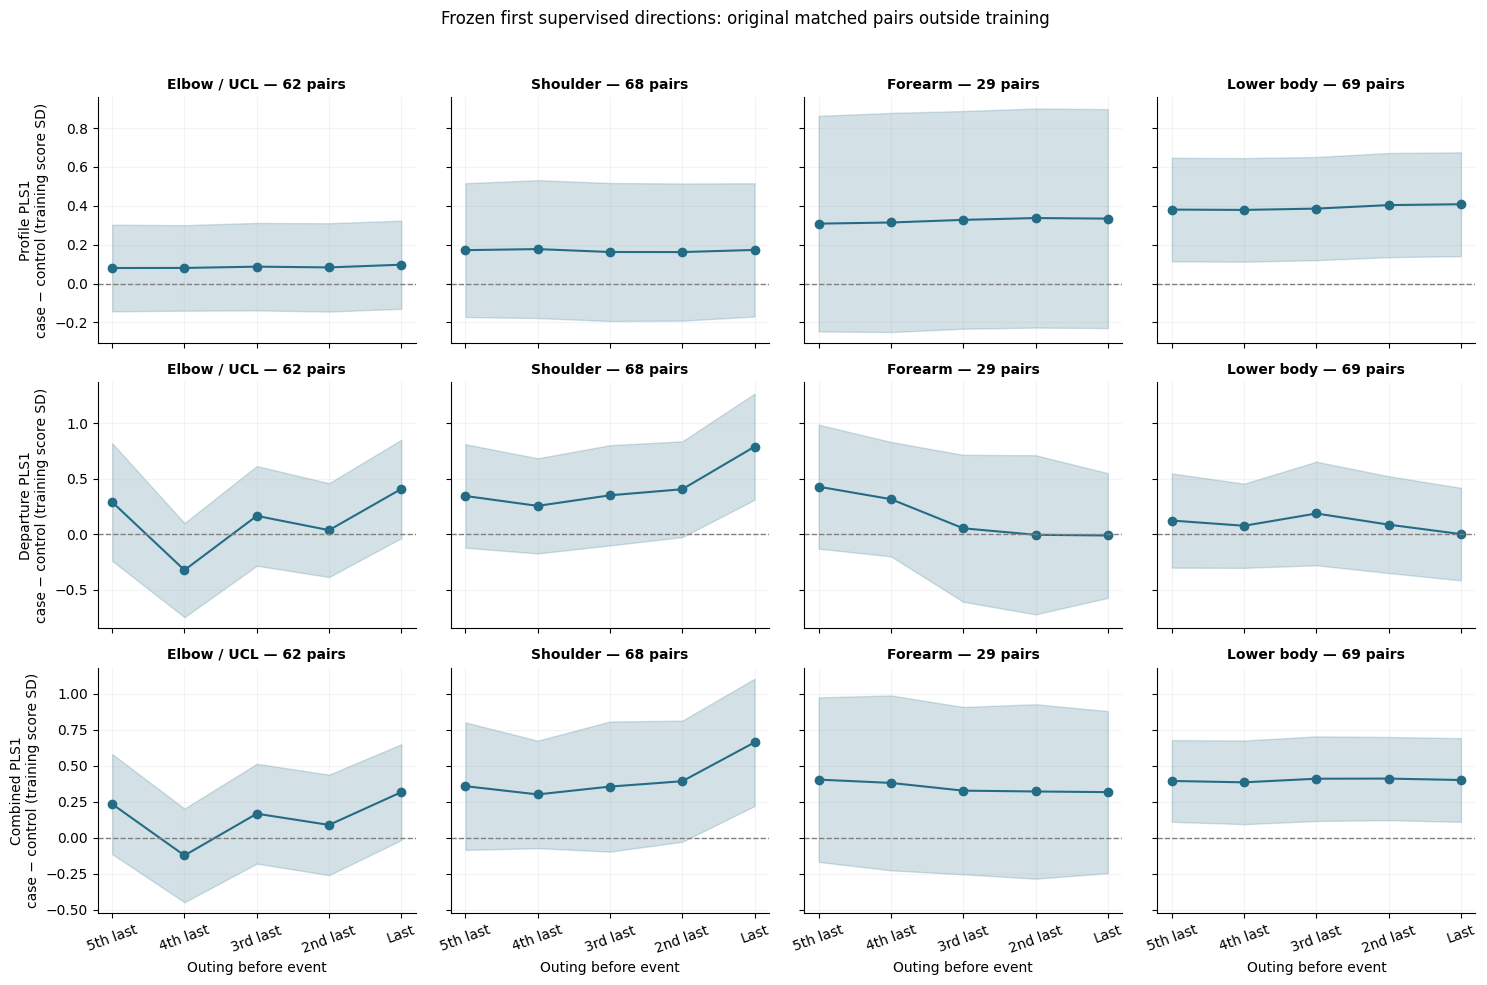

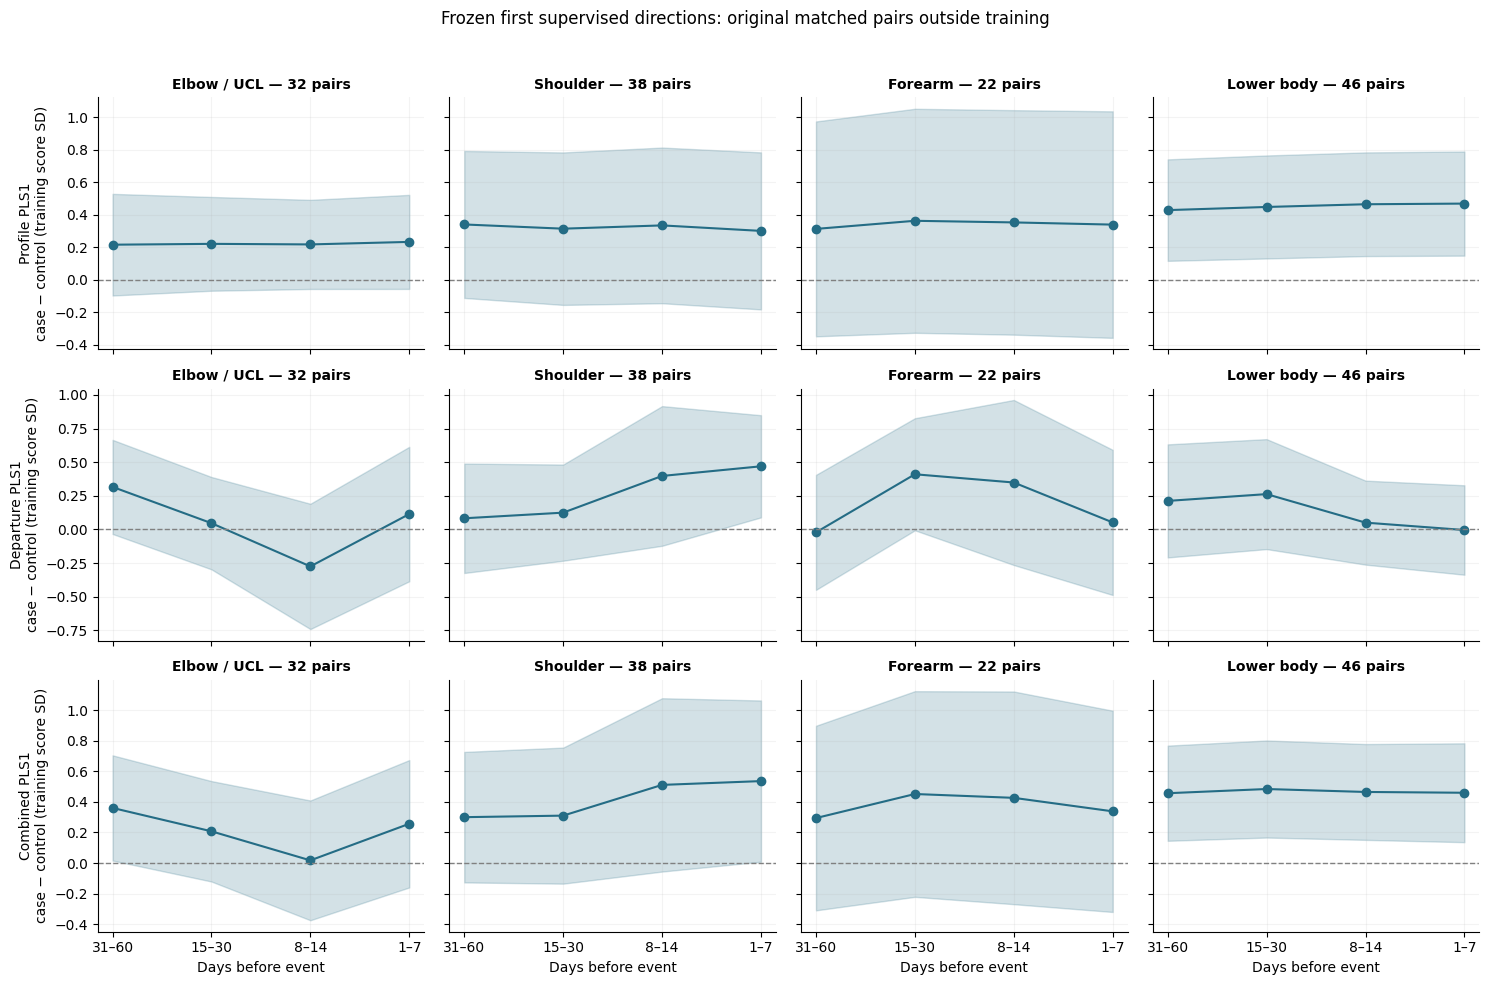

,category,block,mode,metric,mean,low,high,events,pitchers
0,Elbow / UCL,Profile,appearance,average_separation,0.085623,-0.119948,0.303735,62,60
1,Elbow / UCL,Profile,appearance,last_minus_first,0.017009,-0.022160,0.059634,62,60
6,Lower body,Profile,appearance,average_separation,0.391436,0.110674,0.647920,69,61
7,Lower body,Profile,appearance,last_minus_first,0.027551,0.004592,0.049359,69,61
10,Shoulder,Profile,appearance,average_separation,0.169447,-0.156226,0.497289,68,68
11,Shoulder,Profile,appearance,last_minus_first,0.001088,-0.064046,0.062226,68,68
14,Elbow / UCL,Profile,calendar,average_separation,0.222152,-0.044064,0.485417,32,32
15,Elbow / UCL,Profile,calendar,last_minus_first,0.017221,-0.103415,0.132181,32,32
20,Lower body,Profile,calendar,average_separation,0.453153,0.129191,0.746649,46,43
21,Lower body,Profile,calendar,last_minus_first,0.040186,-0.006034,0.083301,46,43


In [4]:
plots.trajectory_figure('appearance');plt.show()
plots.trajectory_figure('calendar');plt.show()
display(read_table('component_shape_contrasts').query("category in ['Shoulder','Elbow / UCL','Lower body']"))

## Interpretation
Ask whether apparent case/control separation is a persistent offset or a changing departure, and whether the uncertainty supports its timing. A direction optimized for injury labels can be informative without representing a distinct physiological mechanism. Continue to the resampling and near-event checks before drawing conclusions.